In [1]:
import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt

with open("../config.yaml") as f:      # notebook lives in notebooks/, so go up one level
    config = yaml.safe_load(f)

rng = np.random.default_rng(config["seed"])   # one seeded generator = reproducible data

In [2]:
def generate_normal_accounts(n, rng):
    """Create n normal (non-abusive) trading accounts."""

    # Age: anywhere from 1 to 900 days since signup
    account_age_days = rng.integers(1, 901, size=n)

    # Baseline: each account's own typical daily trades.
    # Lognormal gives a median of ~8 with a long tail of heavy traders.
    baseline = rng.lognormal(mean=np.log(8), sigma=0.8, size=n)

    # Recent trades/day = baseline * small random wobble (~20%).
    # So normal accounts stay close to their own usual pace.
    trades_per_day = baseline * rng.lognormal(mean=0, sigma=0.2, size=n)

    # Linked accounts: mostly 0, sometimes 1, rarely 2
    linked_account_count = rng.choice([0, 1, 2], size=n, p=[0.75, 0.22, 0.03])

    # Timing regularity: variation in gaps between trades.
    # Humans are irregular, so values sit around 1.0, and we keep a floor of 0.45.
    timing_regularity = np.clip(rng.normal(loc=1.0, scale=0.25, size=n), 0.45, 2.0)

    # Order sources: 1 for most, 2 for some
    alert_source_count = rng.choice([1, 2], size=n, p=[0.7, 0.3])

    return pd.DataFrame({
        "account_age_days": account_age_days,
        "trades_per_day": trades_per_day.round(2),
        "baseline_trades_per_day": baseline.round(2),
        "linked_account_count": linked_account_count,
        "timing_regularity": timing_regularity.round(3),
        "alert_source_count": alert_source_count,
    })

normal = generate_normal_accounts(config["accounts"]["n_normal"], rng)
normal.head()

,account_age_days,trades_per_day,baseline_trades_per_day,linked_account_count,timing_regularity,alert_source_count
0,81,18.66,17.28,0,0.607,2
1,697,4.43,4.48,0,0.734,2
2,590,5.02,4.04,0,0.932,2
3,395,10.21,11.56,0,0.639,1
4,390,21.49,17.64,1,0.898,1


In [3]:
normal.describe().round(2)

,account_age_days,trades_per_day,baseline_trades_per_day,linked_account_count,timing_regularity,alert_source_count
count,3000.00,3000.00,3000.00,3000.00,3000.00,3000.00
mean,451.50,11.15,10.91,0.28,1.00,1.32
std,260.67,11.19,10.57,0.51,0.25,0.47
min,1.00,0.48,0.69,0.00,0.45,1.00
25%,224.00,4.54,4.59,0.00,0.83,1.00
50%,448.00,7.94,7.94,0.00,0.99,1.00
75%,679.25,13.65,13.29,0.00,1.16,2.00
max,900.00,150.09,126.81,2.00,2.00,2.00


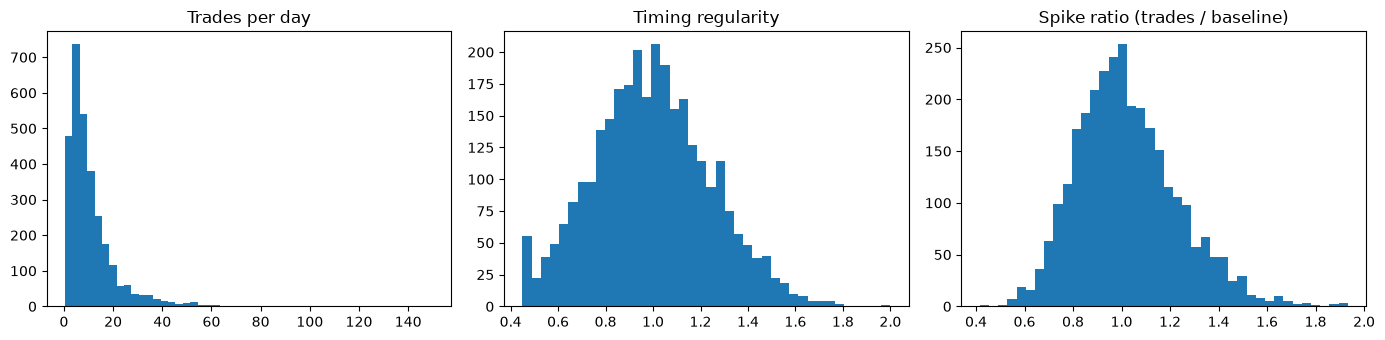

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
axes[0].hist(normal["trades_per_day"], bins=50);       axes[0].set_title("Trades per day")
axes[1].hist(normal["timing_regularity"], bins=40);    axes[1].set_title("Timing regularity")
axes[2].hist(normal["trades_per_day"] / normal["baseline_trades_per_day"], bins=40)
axes[2].set_title("Spike ratio (trades / baseline)")
plt.tight_layout(); plt.show()

In [5]:
def split_counts(n, subtle_fraction):
    """Split n accounts into (n_obvious, n_subtle)."""
    n_subtle = int(round(n * subtle_fraction))
    return n - n_subtle, n_subtle


def generate_trial_abuse(n, subtle_fraction, rng):
    """Brand-new accounts trading far above their own baseline."""
    n_obvious, n_subtle = split_counts(n, subtle_fraction)
    df = generate_normal_accounts(n, rng)          # start from a normal-looking account

    # Multiplier on the account's baseline: obvious 10-30x, subtle 3-5x
    multiplier = np.concatenate([
        rng.uniform(10, 30, size=n_obvious),
        rng.uniform(3, 5, size=n_subtle),
    ])

    df["account_age_days"] = rng.integers(0, 4, size=n)          # 0-3 days old
    df["trades_per_day"] = (df["baseline_trades_per_day"] * multiplier).round(2)
    df["difficulty"] = ["obvious"] * n_obvious + ["subtle"] * n_subtle
    df["anomaly_type"] = "trial_abuse"
    return df


def generate_multi_account(n, subtle_fraction, rng):
    """Accounts sharing a device/IP with many other accounts."""
    n_obvious, n_subtle = split_counts(n, subtle_fraction)
    df = generate_normal_accounts(n, rng)

    # Obvious: 6-12 linked accounts. Subtle: 3-4 linked accounts.
    df["linked_account_count"] = np.concatenate([
        rng.integers(6, 13, size=n_obvious),     # upper bound is exclusive, so 13
        rng.integers(3, 5, size=n_subtle),
    ])
    df["difficulty"] = ["obvious"] * n_obvious + ["subtle"] * n_subtle
    df["anomaly_type"] = "multi_account"
    return df


def generate_bots(n, subtle_fraction, rng):
    """Accounts trading with machine-like, very regular timing."""
    n_obvious, n_subtle = split_counts(n, subtle_fraction)
    df = generate_normal_accounts(n, rng)

    # Obvious: timing near zero. Subtle: just below the normal floor of 0.45.
    df["timing_regularity"] = np.concatenate([
        rng.uniform(0.01, 0.10, size=n_obvious),
        rng.uniform(0.30, 0.44, size=n_subtle),
    ]).round(3)
    df["difficulty"] = ["obvious"] * n_obvious + ["subtle"] * n_subtle
    df["anomaly_type"] = "bot"
    return df

In [6]:
n_abuse = config["accounts"]["n_per_abuse_type"]
frac = config["accounts"]["subtle_fraction"]

trial = generate_trial_abuse(n_abuse, frac, rng)
multi = generate_multi_account(n_abuse, frac, rng)
bots  = generate_bots(n_abuse, frac, rng)

# Normal accounts get label columns too, so everything stacks into one table
normal["anomaly_type"] = "normal"
normal["difficulty"] = "none"

all_accounts = pd.concat([normal, trial, multi, bots], ignore_index=True)

# Shuffle so abusers are not all sitting at the bottom, then assign IDs
all_accounts = all_accounts.sample(frac=1, random_state=config["seed"]).reset_index(drop=True)
all_accounts["account_id"] = [f"ACC{i:05d}" for i in range(len(all_accounts))]
all_accounts["is_anomaly"] = (all_accounts["anomaly_type"] != "normal").astype(int)

feature_cols = ["account_id", "account_age_days", "trades_per_day",
                "baseline_trades_per_day", "linked_account_count",
                "timing_regularity", "alert_source_count"]
label_cols = ["account_id", "is_anomaly", "anomaly_type", "difficulty"]

features = all_accounts[feature_cols]
labels = all_accounts[label_cols]

features.to_csv("../" + config["paths"]["features"], index=False)
labels.to_csv("../" + config["paths"]["labels"], index=False)

print(features.shape, labels.shape)
print(labels["is_anomaly"].mean().round(4))
labels.groupby(["anomaly_type", "difficulty"]).size()

(3099, 7) (3099, 4)
0.0319


anomaly_type   difficulty
bot            obvious         17
               subtle          16
multi_account  obvious         17
               subtle          16
normal         none          3000
trial_abuse    obvious         17
               subtle          16
dtype: int64

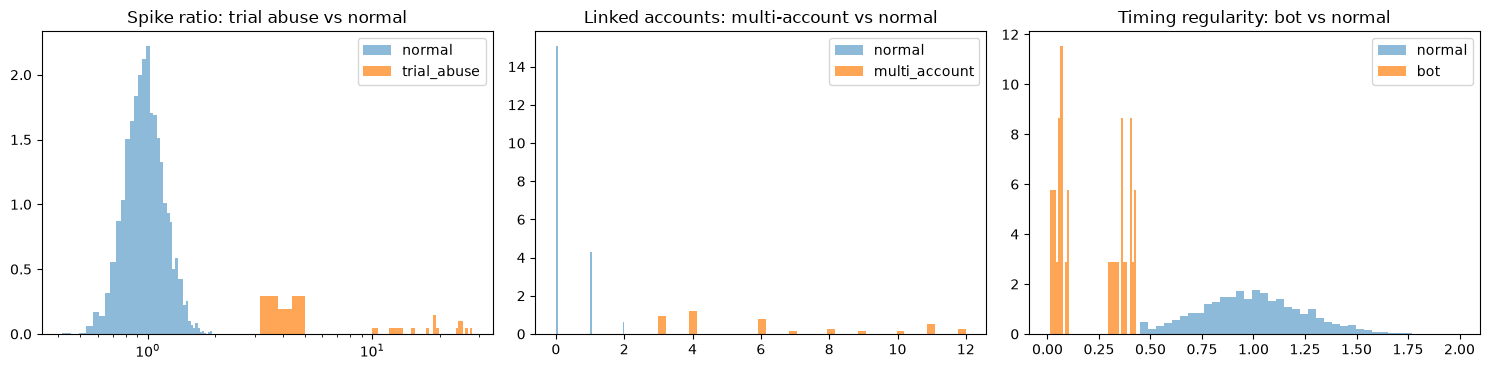

,account_id,account_age_days,trades_per_day,baseline_trades_per_day,linked_account_count,timing_regularity,alert_source_count
0,ACC00000,691,9.46,8.43,0,0.702,1
1,ACC00001,471,3.32,3.38,0,0.992,1
2,ACC00002,38,7.84,7.02,0,0.581,1
3,ACC00003,630,11.42,11.82,0,1.025,2
4,ACC00004,478,1.90,1.31,0,1.548,1
